# 0. Setup

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import random
import json
import warnings
import copy
warnings.filterwarnings("ignore", category=DeprecationWarning)

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

VOCAB, START, PAD = 20, 18, 19
CTX        = 16
FADE_LIMIT = 6
WINS = [{0,1,2},{3,4,5},{6,7,8},{0,3,6},{1,4,7},{2,5,8},{0,4,8},{2,4,6}]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def check_win(sqs): return any(w <= sqs for w in WINS)
def get_window(seq): return seq[-FADE_LIMIT:] if len(seq) > FADE_LIMIT else seq
def is_x_turn(seq): return not seq or seq[-1] >= 9
def is_illegal(move, window):
    is_x      = is_x_turn(window)
    taken     = {t % 9 for t in window}
    wrong_turn = (move < 9) != is_x
    occupied   = move % 9 in taken
    return wrong_turn or occupied

# 1. Data

In [2]:
FADING_DISCOUNT = 0.95
CONVERGENCE_EPS = 1e-5
OPTIMAL_RATIO   = 0.80
OPTIMAL_EPS     = 1e-4

def build_graph():
    graph = {}
    visited = {()}
    queue = [()]

    while queue:
        state = queue.pop(0)
        x_squares = {t     for t in state if t < 9}
        o_squares = {t - 9 for t in state if t >= 9}

        if check_win(x_squares):
            graph[state] = {"value": 1.0, "next_states": []}
            continue
        if check_win(o_squares):
            graph[state] = {"value": -1.0, "next_states": []}
            continue

        is_x = is_x_turn(state)
        free_squares = set(range(9)) - x_squares - o_squares

        next_states = []
        for sq in free_squares:
            token = sq if is_x else sq + 9
            next_state = get_window(state + (token,))
            next_states.append(next_state)
            if next_state not in visited:
                visited.add(next_state)
                queue.append(next_state)

        graph[state] = {"value": 0.0, "next_states": next_states}

    return graph

def fading_minimax(graph):
    values_changed = True
    while values_changed:
        values_changed = False
        for state, node in graph.items():
            if not node["next_states"]:
                continue

            successor_values = []
            for next_state in node["next_states"]:
                successor_values.append(graph[next_state]["value"])

            pick_best = max if is_x_turn(state) else min
            new_value = pick_best(successor_values) * FADING_DISCOUNT

            if abs(node["value"] - new_value) > CONVERGENCE_EPS:
                values_changed = True

            node["value"] = new_value

    return graph

def sample_games(graph, n=50_000):
    sequences = []
    for _ in range(n):
        state = ()
        seq = [START]

        for _ in range(CTX):
            node = graph[state]
            if not node["next_states"]:
                break

            pick_best = max if is_x_turn(state) else min
            best_value = pick_best(graph[next_state]["value"] for next_state in node["next_states"])

            if random.random() < OPTIMAL_RATIO:
                pool = [ns for ns in node["next_states"] if abs(graph[ns]["value"] - best_value) < OPTIMAL_EPS]
            else:
                pool = node["next_states"]

            state = random.choice(pool)
            seq.append(state[-1])

        seq += [PAD] * (CTX + 1 - len(seq))
        sequences.append(seq)

    return torch.tensor(sequences, device=DEVICE)

def build_dataset():
    print("Building game graph...")
    graph = build_graph()

    print("Computing minimax values...")
    graph = fading_minimax(graph)

    print("Sampling games...")
    return sample_games(graph)

xs = build_dataset()
print(xs[:3])

Building game graph...
Computing minimax values...
Sampling games...
tensor([[18,  1, 15,  4, 16,  8,  9,  2, 14,  6, 10,  4, 19, 19, 19, 19, 19],
        [18,  5,  9,  3, 13,  8, 10,  7, 14,  6, 19, 19, 19, 19, 19, 19, 19],
        [18,  5,  9,  4, 12,  1, 15, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19]],
       device='cuda:0')


# 2. Models

In [3]:
class TicTacToe1Head(nn.Module):
    """Single-head attention."""
    def __init__(self):
        super().__init__()
        D = 32
        self.D       = D
        self.tok     = nn.Embedding(VOCAB, D)
        self.pos     = nn.Embedding(CTX, D)
        self.WQ      = nn.Linear(D, D, bias=False)
        self.WK      = nn.Linear(D, D, bias=False)
        self.WV      = nn.Linear(D, D, bias=False)
        self.mlp_in  = nn.Linear(D, 4*D)
        self.mlp_out = nn.Linear(4*D, D)
        self.ln1     = nn.LayerNorm(D)
        self.ln2     = nn.LayerNorm(D)
        self.unembed = nn.Linear(D, VOCAB, bias=False)
        self.register_buffer("mask", torch.tril(torch.ones(CTX, CTX)))

    def forward(self, tokens):
        B, T         = tokens.shape
        tok_emb      = self.tok(tokens)
        x_after_pos  = tok_emb + self.pos(torch.arange(T, device=tokens.device))
        
        xn1          = self.ln1(x_after_pos)
        Q            = self.WQ(xn1)
        K            = self.WK(xn1)
        V            = self.WV(xn1)
        a            = (Q @ K.transpose(-2, -1))
        a_scaled     = a * (self.D ** -0.5)
        a_masked     = a_scaled.masked_fill(self.mask[:T, :T] == 0, float('-inf'))
        attn         = F.softmax(a_masked, dim=-1)
        attn_out     = attn @ V
        x_after_attn = x_after_pos + attn_out
        
        xn2          = self.ln2(x_after_attn)
        mlp_act      = F.gelu(self.mlp_in(xn2))
        mlp_out      = self.mlp_out(mlp_act)
        x_after_mlp  = x_after_attn + mlp_out
        
        logits       = self.unembed(x_after_mlp)
        return {
            "tok_emb":      tok_emb[0].detach().cpu(),
            "x_after_pos":  x_after_pos[0].detach().cpu(),
            "xn1":          xn1[0].detach().cpu(),
            "Q":            [Q[0].detach().cpu()],
            "K":            [K[0].detach().cpu()],
            "V":            [V[0].detach().cpu()],
            "a":            [a[0].detach().cpu()],
            "attention":    [attn[0].detach().cpu()],
            "attn_out":     [attn_out[0].detach().cpu()],
            "x_after_attn": x_after_attn[0].detach().cpu(),
            "xn2":          xn2[0].detach().cpu(),
            "mlp_act":      mlp_act[0].detach().cpu(),
            "mlp_out":      mlp_out,
            "x_after_mlp":  x_after_mlp[0].detach().cpu(),
            "logits":       logits,
        }


class TicTacToe2Head(nn.Module):
    """Two-head attention."""
    def __init__(self):
        super().__init__()
        self.D       = 32
        self.d       = 16
        self.tok     = nn.Embedding(VOCAB, self.D)
        self.pos     = nn.Embedding(CTX,   self.D)
        self.WQ1     = nn.Linear(self.D, self.d, bias=False)
        self.WK1     = nn.Linear(self.D, self.d, bias=False)
        self.WV1     = nn.Linear(self.D, self.d, bias=False)
        self.WQ2     = nn.Linear(self.D, self.d, bias=False)
        self.WK2     = nn.Linear(self.D, self.d, bias=False)
        self.WV2     = nn.Linear(self.D, self.d, bias=False)
        self.proj    = nn.Linear(self.D, self.D, bias=False)
        self.mlp_in  = nn.Linear(self.D, 4*self.D)
        self.mlp_out = nn.Linear(4*self.D, self.D)
        self.ln1     = nn.LayerNorm(self.D)
        self.ln2     = nn.LayerNorm(self.D)
        self.unembed = nn.Linear(self.D, VOCAB, bias=False)
        self.register_buffer("mask", torch.tril(torch.ones(CTX, CTX)))

    def forward(self, tokens):
        B, T         = tokens.shape
        tok_emb      = self.tok(tokens)
        x_after_pos  = tok_emb + self.pos(torch.arange(T, device=tokens.device))
        
        xn1          = self.ln1(x_after_pos)
        Q1           = self.WQ1(xn1)
        K1           = self.WK1(xn1)
        V1           = self.WV1(xn1)
        a1           = Q1 @ K1.transpose(-2, -1)
        a1_scaled    = a1 * (self.d ** -0.5)
        a_masked1    = a1_scaled.masked_fill(self.mask[:T, :T] == 0, float('-inf'))
        attn1        = F.softmax(a_masked1, dim=-1)
        attn_out1    = attn1 @ V1
        
        Q2           = self.WQ2(xn1)
        K2           = self.WK2(xn1)
        V2           = self.WV2(xn1)
        a2           = Q2 @ K2.transpose(-2, -1)
        a2_scaled    = a2 * (self.d ** -0.5)
        a_masked2    = a2_scaled.masked_fill(self.mask[:T, :T] == 0, float('-inf'))
        attn2        = F.softmax(a_masked2, dim=-1)
        attn_out2    = attn2 @ V2
        x_after_attn = x_after_pos + self.proj(torch.cat([attn_out1, attn_out2], dim=-1))
        
        xn2          = self.ln2(x_after_attn)
        mlp_act      = F.gelu(self.mlp_in(xn2))
        mlp_out      = self.mlp_out(mlp_act)
        x_after_mlp  = x_after_attn + mlp_out
        
        logits       = self.unembed(x_after_mlp)
        return {
            "tok_emb":      tok_emb[0].detach().cpu(),
            "x_after_pos":  x_after_pos[0].detach().cpu(),
            "xn1":          xn1[0].detach().cpu(),
            "Q":            [Q1[0].detach().cpu(),        Q2[0].detach().cpu()],
            "K":            [K1[0].detach().cpu(),        K2[0].detach().cpu()],
            "V":            [V1[0].detach().cpu(),        V2[0].detach().cpu()],
            "a":            [a1[0].detach().cpu(),        a2[0].detach().cpu()],
            "attention":    [attn1[0].detach().cpu(),     attn2[0].detach().cpu()],
            "attn_out":     [attn_out1[0].detach().cpu(), attn_out2[0].detach().cpu()],
            "x_after_attn": x_after_attn[0].detach().cpu(),
            "xn2":          xn2[0].detach().cpu(),
            "mlp_act":      mlp_act[0].detach().cpu(),
            "mlp_out":      mlp_out,
            "x_after_mlp":  x_after_mlp[0].detach().cpu(),
            "logits":       logits,
        }

# 3. Training

In [4]:
def train(model, steps=30_000, batch=512):
    opt   = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.05)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    name  = model.__class__.__name__
    print(f"Training {name} for {steps} steps...")
    for step in range(steps + 1):
        sample_idx = torch.randint(0, len(xs), (batch,), device=DEVICE)
        tokens     = xs[sample_idx]
        out        = model(tokens[:, :-1])
        loss       = F.cross_entropy(out["logits"].reshape(-1, VOCAB), tokens[:, 1:].reshape(-1), ignore_index=PAD)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step % 5000 == 0: print(f"  step {step:5d} | loss {loss.item():.4f}")
    print(f"{name} done.\n")

tictactoe1head = TicTacToe1Head().to(DEVICE);  train(tictactoe1head)
tictactoe2head = TicTacToe2Head().to(DEVICE);  train(tictactoe2head)

Training TicTacToe1Head for 30000 steps...
  step     0 | loss 3.3648
  step  5000 | loss 0.9139
  step 10000 | loss 0.8852
  step 15000 | loss 0.8768
  step 20000 | loss 0.8510
  step 25000 | loss 0.8446
  step 30000 | loss 0.8535
TicTacToe1Head done.

Training TicTacToe2Head for 30000 steps...
  step     0 | loss 3.1754
  step  5000 | loss 0.9186
  step 10000 | loss 0.8748
  step 15000 | loss 0.8397
  step 20000 | loss 0.8581
  step 25000 | loss 0.8438
  step 30000 | loss 0.8506
TicTacToe2Head done.



# 4. Visualisation

In [5]:
@torch.no_grad()
def play(model, moves_str=None):
    history = [int(m[1:]) if m[0] == "X" else int(m[1:]) + 9
               for m in (moves_str or [])]
    window = get_window(history)
    x_sqs  = {t     for t in window if t < 9}
    o_sqs  = {t - 9 for t in window if t >= 9}
    x_seq  = [t     for t in window if t < 9]
    o_seq  = [t - 9 for t in window if t >= 9]
    fading_x = x_seq[0] if len(x_seq) == 3 else None
    fading_o = o_seq[0] if len(o_seq) == 3 else None

    # Pick move
    seq       = [START] + history[-CTX+1:]
    tokens    = torch.tensor([seq], device=DEVICE)
    out       = model(tokens)
    logits    = out["logits"]
    attn_maps = out["attention"]
    move = int(torch.argmax(logits[0, -1].cpu()))
    symbol    = "X" if move < 9 else "O"
    square    = move % 9

    # Cheks
    if check_win(x_sqs): print("✓ X wins!"); return
    if check_win(o_sqs): print("✓ O wins!"); return
    illegal = is_illegal(move, window)
    if illegal: print(f"✗ Illegal move: {symbol}{square}")
    else:       print(f"{moves_str}  →  {symbol}{square}")

    # Board
    fig, axes = plt.subplots(1, 1 + len(attn_maps), figsize=(5*len(attn_maps) + 5, 4))
    ax_board  = axes[0]
    ax_board.set_xlim(0, 3); ax_board.set_ylim(0, 3); ax_board.axis("off")
    for i in range(1, 3):
        ax_board.axhline(i, color="#999"); ax_board.axvline(i, color="#999")
    for s in range(9):
        col, row = s % 3, 2 - s // 3
        if   s == square and not illegal: sym, color = symbol, "#2ecc71"
        elif s in x_sqs:                  sym, color = "X", "#cccccc" if s == fading_x else "#555555"
        elif s in o_sqs:                  sym, color = "O", "#cccccc" if s == fading_o else "#555555"
        else: continue
        ax_board.text(col+.5, row+.5, sym, ha="center", va="center",
                      fontsize=36, fontweight="bold", color=color)

    # Attention
    labels = ["S"] + [f"{'X' if t<9 else 'O'}{t%9}" for t in history[-CTX+1:]]
    n = len(labels)
    for i, attn in enumerate(attn_maps):
        ax = axes[1 + i]
        im = ax.imshow(attn[:n, :n].numpy(), cmap="YlOrRd", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(n)); ax.set_xticklabels(labels, fontsize=9)
        ax.set_yticks(range(n)); ax.set_yticklabels(labels, fontsize=9)
        ax.set_title(f"Attention head {i+1}" if len(attn_maps) > 1 else "Attention weights")

    plt.suptitle(model.__class__.__name__, fontweight="bold")
    plt.tight_layout(); plt.show()

['X4', 'O0', 'X2', 'O6', 'X1', 'O8', 'X3', '05', 'X4', 'O7']  →  X6


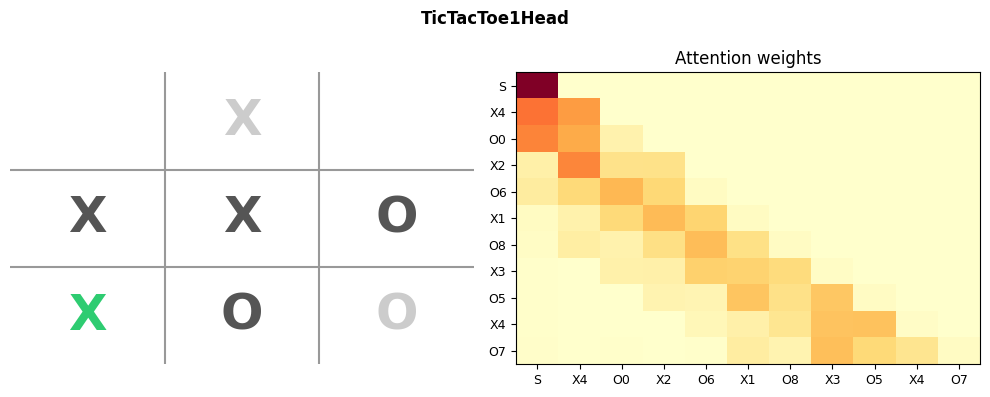

['X4', 'O0', 'X2', 'O6', 'X1', 'O8', 'X3', '05', 'X4', 'O7']  →  X0


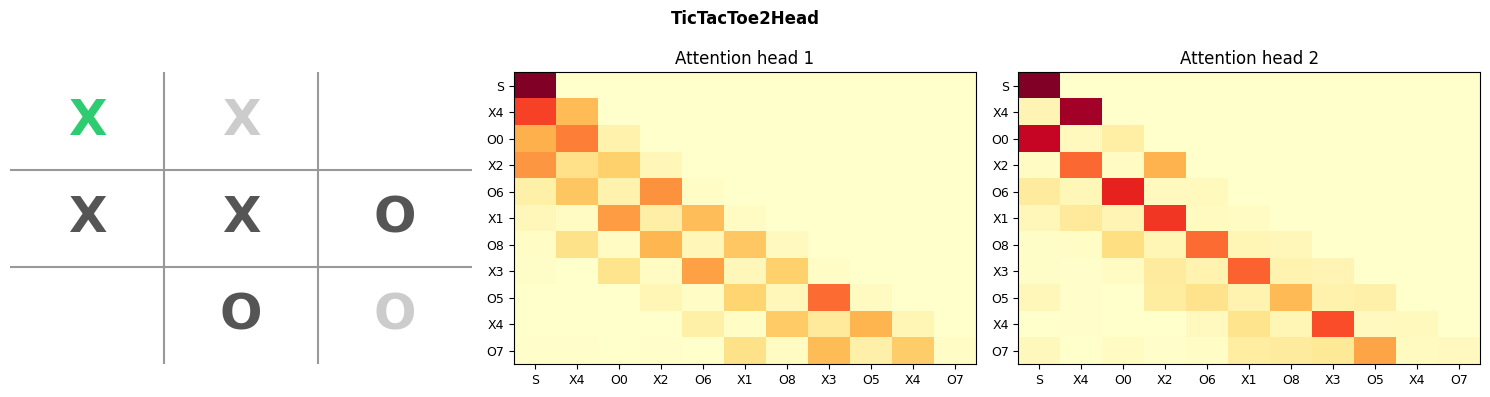

In [6]:
game = ["X4", "O0", "X2", "O6", "X1", "O8", "X3", "05", "X4", "O7"]
play(tictactoe1head, game)
play(tictactoe2head, game)

# 5. Export

In [7]:
_dummy = torch.zeros(1, CTX, dtype=torch.long, device=DEVICE)

class _W(nn.Module):
    def __init__(self, m): super().__init__(); self.m = m
    def forward(self, t):
        d = self.m(t)
        return (
            d.get("tok_emb",      torch.zeros(0)),
            d.get("x_after_pos",  torch.zeros(0)),
            d.get("xn1",          torch.zeros(0)),
            torch.stack(d["Q"])        if d.get("Q")        else torch.zeros(0),
            torch.stack(d["K"])        if d.get("K")        else torch.zeros(0),
            torch.stack(d["V"])        if d.get("V")        else torch.zeros(0),
            torch.stack(d["a"])        if d.get("a")        else torch.zeros(0),
            torch.stack(d["attention"])if d.get("attention")else torch.zeros(0),
            torch.stack(d["attn_out"]) if d.get("attn_out") else torch.zeros(0),
            d.get("x_after_attn", torch.zeros(0)),
            d.get("xn2",          torch.zeros(0)),
            d.get("mlp_act",      torch.zeros(0)),
            d.get("mlp_out",      torch.zeros(0)),
            d.get("x_after_mlp",  torch.zeros(0)),
            d["logits"],
        )

_KEYS = ["tok_emb", "x_after_pos",
         "xn1", "Q", "K", "V", "a", "attention", "attn_out", "x_after_attn",
         "xn2", "mlp_act", "mlp_out", "x_after_mlp",
         "logits"]

for model, path in [
    (tictactoe1head,    "tictactoe1head.onnx"),
    (tictactoe2head,    "tictactoe2head.onnx"),
]:
    model.eval()
    torch.onnx.export(
        _W(model), _dummy, path,
        input_names=["tokens"],
        output_names=_KEYS,
        dynamic_axes={"tokens": {0: "batch", 1: "seq"}, "logits": {0: "batch", 1: "seq"}},
        opset_version=17, do_constant_folding=True, dynamo=False,
    )
    print(f"Exported ONNX model → {path}")

Exported ONNX model → tictactoe1head.onnx
Exported ONNX model → tictactoe2head.onnx


In [8]:
import json

PRECISION = 4

def _to_rounded_list(data):
    if isinstance(data, dict):
        return {k: _to_rounded_list(v) for k, v in data.items()}
    if isinstance(data, list):
        return [_to_rounded_list(x) for x in data]
    return round(float(data), PRECISION)

def _save(name, data):
    path = f"{name}.json"
    with open(path, 'w') as f:
        json.dump(_to_rounded_list(data), f, indent=2)
    print(f"Exported → {path}")

def _tensor(t):
    return t.detach().cpu().numpy().tolist()

def export_tictactoe1head(model, prefix="tictactoe1head"):
    m = model
    _save(f"{prefix}_embedding",
          {"weight": _tensor(m.tok.weight)})
    _save(f"{prefix}_pos_encoding",
          {"weight": _tensor(m.pos.weight)})
    _save(f"{prefix}_ln1",
          {"weight": _tensor(m.ln1.weight),
           "bias":   _tensor(m.ln1.bias)})
    _save(f"{prefix}_attention", {
          "WQ": {"weight": _tensor(m.WQ.weight)},
          "WK": {"weight": _tensor(m.WK.weight)},
          "WV": {"weight": _tensor(m.WV.weight)},
    })
    _save(f"{prefix}_ln2",
          {"weight": _tensor(m.ln2.weight),
           "bias":   _tensor(m.ln2.bias)})
    _save(f"{prefix}_mlp", {
          "mlp_in":  {"weight": _tensor(m.mlp_in.weight),
                      "bias":   _tensor(m.mlp_in.bias)},
          "mlp_out": {"weight": _tensor(m.mlp_out.weight),
                      "bias":   _tensor(m.mlp_out.bias)},
    })
    _save(f"{prefix}_unembed",
          {"weight": _tensor(m.unembed.weight)})

def export_tictactoe2head(model, prefix="tictactoe2head"):
    m = model
    _save(f"{prefix}_attention", {
          "WQ1":  {"weight": _tensor(m.WQ1.weight)},
          "WK1":  {"weight": _tensor(m.WK1.weight)},
          "WV1":  {"weight": _tensor(m.WV1.weight)},
          "WQ2":  {"weight": _tensor(m.WQ2.weight)},
          "WK2":  {"weight": _tensor(m.WK2.weight)},
          "WV2":  {"weight": _tensor(m.WV2.weight)},
          "proj": {"weight": _tensor(m.proj.weight)},
    })

tictactoe1head.eval(); export_tictactoe1head(tictactoe1head)
tictactoe2head.eval(); export_tictactoe2head(tictactoe2head)

Exported → tictactoe1head_embedding.json
Exported → tictactoe1head_pos_encoding.json
Exported → tictactoe1head_ln1.json
Exported → tictactoe1head_attention.json
Exported → tictactoe1head_ln2.json
Exported → tictactoe1head_mlp.json
Exported → tictactoe1head_unembed.json
Exported → tictactoe2head_attention.json
